# Grover

In [1]:
import pennylane as qml
import numpy as np
import matplotlib.pyplot as plt

## Lista de palavras e palavra procurada

In [2]:
words = ["AZUL", "VERDE", "ROSA", "PRETO", "BRANCO", "ROXO", "CINZA", "AMARELO"]
target = "ROXO"
word_length = max(map(len, words))
letter_codes = {letter: code for code, letter in enumerate(" ABCDEFGHIJKLMNOPQRSTUVWXYZ")}


def encode_word(word):
    return [letter_codes[letter] for letter in word.ljust(word_length)]


encoded_words = [encode_word(word) for word in words]
search_wires = list(range(3))
letter_wires = list(range(3, 8))
match_wires = list(range(8, 8 + word_length))
iterations = 2
device = qml.device("default.qubit", wires=8 + word_length)

print("Lista de palavras:", words)
print(f"Palavra procurada: {target!r}")

Lista de palavras: ['AZUL', 'VERDE', 'ROSA', 'PRETO', 'BRANCO', 'ROXO', 'CINZA', 'AMARELO']
Palavra procurada: 'ROXO'


## Oráculo

A memória carrega cada letra em superposição. O circuito compara as letras com a palavra procurada, marca a correspondência completa e desfaz os registros auxiliares. São 3 qubits para as posições, 5 para uma letra e 7 para as comparações. A preparação dessa memória também tem custo.

In [ ]:
def load_letter(position):
    operations = [qml.BasisEmbedding(word[position], wires=letter_wires) for word in encoded_words]
    qml.Select(operations, control=search_wires)


def compare_letters(target_codes):
    for position, code in enumerate(target_codes):
        load_letter(position)
        bits = [int(bit) for bit in format(code, "05b")]
        qml.MultiControlledX(wires=letter_wires + [match_wires[position]], control_values=bits)
        qml.adjoint(load_letter)(position)


def oracle(target_codes):
    compare_letters(target_codes)
    qml.ctrl(qml.PauliZ, control=match_wires[:-1])(wires=match_wires[-1])
    qml.adjoint(compare_letters)(target_codes)

## Circuito

In [4]:
@qml.qnode(device)
def grover(target):
    target_codes = encode_word(target)

    for wire in search_wires:
        qml.Hadamard(wires=wire)

    for _ in range(iterations):
        oracle(target_codes)
        qml.GroverOperator(wires=search_wires)

    return qml.probs(wires=search_wires)

## Resultado

In [5]:
probabilities = grover(target)
found_state = int(np.argmax(probabilities))
found_word = words[found_state]

print("Lista pesquisada:", words)
print(f"Palavra procurada: {target!r}")
print(f"Palavra encontrada: {found_word!r}")
print(f"Probabilidade: {probabilities[found_state]:.2%}")

Lista pesquisada: ['AZUL', 'VERDE', 'ROSA', 'PRETO', 'BRANCO', 'ROXO', 'CINZA', 'AMARELO']
Palavra procurada: 'ROXO'
Palavra encontrada: 'ROXO'
Probabilidade: 94.53%


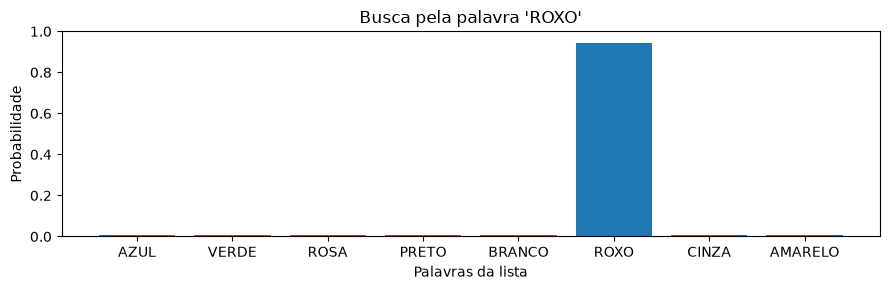

In [6]:
plt.figure(figsize=(9, 3))
plt.bar(words, probabilities)
plt.title(f"Busca pela palavra '{target}'")
plt.xlabel("Palavras da lista")
plt.ylabel("Probabilidade")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## Busca sem resultado: ABACATE

Sem uma palavra correspondente, o oráculo não marca nenhuma posição e as probabilidades permanecem uniformes: 12,5% para cada palavra. O circuito ainda retorna uma posição da lista, por isso verificamos o candidato ao final. Um candidato incorreto, isoladamente, não comprova a ausência do alvo.

In [ ]:
missing_target = "ABACATE"
missing_probabilities = grover(missing_target)
candidate = words[int(np.argmax(missing_probabilities))]

print("Lista pesquisada:", words)
print(f"Palavra procurada: {missing_target!r}")
print(f"Candidato obtido: {candidate!r}")
print("Resultado:", "Palavra encontrada." if candidate == missing_target else "Palavra não encontrada nesta execução.")
print("Probabilidades:", dict(zip(words, np.round(missing_probabilities, 4))))

Lista pesquisada: ['AZUL', 'VERDE', 'ROSA', 'PRETO', 'BRANCO', 'ROXO', 'CINZA', 'AMARELO']
Palavra procurada: 'ABACATE'
Candidato obtido: 'VERDE'
Resultado: Palavra não encontrada nesta execução.
Probabilidades: {'AZUL': np.float64(0.125), 'VERDE': np.float64(0.125), 'ROSA': np.float64(0.125), 'PRETO': np.float64(0.125), 'BRANCO': np.float64(0.125), 'ROXO': np.float64(0.125), 'CINZA': np.float64(0.125), 'AMARELO': np.float64(0.125)}


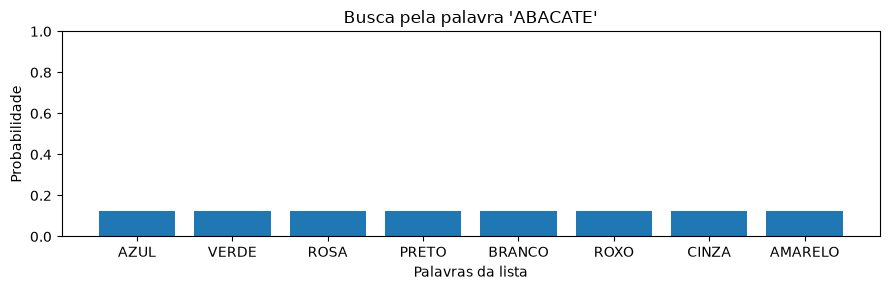

In [8]:
plt.figure(figsize=(9, 3))
plt.bar(words, missing_probabilities)
plt.title(f"Busca pela palavra '{missing_target}'")
plt.xlabel("Palavras da lista")
plt.ylabel("Probabilidade")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()